# Chapitre 4 - Lab : évolution de schéma dans PostgreSQL

Ce lab confronte le cours 4 (flux de données par les bases) à un vrai moteur,
PostgreSQL 16. Nous allons :

1. ajouter une colonne **sans réécrire** la table, et voir où PostgreSQL range la valeur
   par défaut ;
2. observer **physiquement** des lignes de plusieurs époques dans les mêmes pages ;
3. comparer avec les changements qui **réécrivent** toute la table ;
4. mesurer le piège des verrous d'un `ALTER TABLE` en production ;
5. faire évoluer des documents JSONB sans effacer les champs inconnus ;
6. comparer les formats texte et binaire du protocole de PostgreSQL.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/encoding/compose.yml -p ddia_encoding up -d     # démarrer
docker compose -f docker/encoding/compose.yml -p ddia_encoding down -v   # arrêter et effacer
```

PostgreSQL écoute sur le port **10532** de la machine (utilisateur, mot de passe et base :
`ddia` / `ddia` / `evolution`).

In [1]:
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg

from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)

DSN = "host=localhost port=10532 user=ddia password=ddia dbname=evolution"
con = None
for essai in range(30):
    try:
        con = psycopg.connect(DSN, autocommit=True)
        break
    except psycopg.OperationalError:
        time.sleep(1)
assert con is not None, "PostgreSQL ne répond pas : avez-vous lancé docker compose up ?"
print(con.execute("SELECT version()").fetchone()[0][:60])
con.execute("CREATE EXTENSION IF NOT EXISTS pageinspect")

def q(sql, params=None, c=None):
    return (c or con).execute(sql, params).fetchall()

def fichier(table):
    """Fichier physique (relfilenode) et taille de la table."""
    return q("SELECT pg_relation_filenode(%s::regclass), pg_relation_size(%s::regclass)", (table, table))[0]

PostgreSQL 16.14 (Debian 16.14-1.pgdg13+1) on x86_64-pc-linu


## 1. Ajouter une colonne sans réécrire (section *Different values written at different times*)

Créons une table d'un million de clients, puis ajoutons une colonne `pays` avec une valeur
par défaut constante. Surveillons le **fichier** de la table (son numéro `relfilenode`) et
sa taille : si PostgreSQL réécrivait la table, il créerait un nouveau fichier.

In [2]:
con.execute("DROP TABLE IF EXISTS clients")
con.execute("CREATE TABLE clients (id int PRIMARY KEY, nom text NOT NULL, solde numeric(12, 2))")
con.execute("""INSERT INTO clients SELECT i, 'client' || i, round((random() * 1000)::numeric, 2)
               FROM generate_series(1, 1000000) AS i""")
con.execute("VACUUM ANALYZE clients")
avant = fichier("clients")
t = time.perf_counter()
con.execute("ALTER TABLE clients ADD COLUMN pays text DEFAULT 'FR'")
duree_add = time.perf_counter() - t
apres = fichier("clients")
print(f"ADD COLUMN ... DEFAULT 'FR' : {duree_add * 1e3:.1f} ms")
print(f"fichier avant : {avant[0]} ({avant[1] / 1e6:.1f} Mo) ; après : {apres[0]} ({apres[1] / 1e6:.1f} Mo)")
pd.DataFrame(q("""SELECT attname, atthasmissing, attmissingval FROM pg_attribute
                  WHERE attrelid = 'clients'::regclass AND attnum > 0 ORDER BY attnum"""),
             columns=["colonne", "valeur manquante gérée ?", "valeur fournie à la lecture"])

ADD COLUMN ... DEFAULT 'FR' : 0.4 ms
fichier avant : 16800 (52.2 Mo) ; après : 16800 (52.2 Mo)


,colonne,valeur manquante gérée ?,valeur fournie à la lecture
0,id,False,NaN
1,nom,False,NaN
2,solde,False,NaN
3,pays,True,{FR}


Quelques millisecondes, même fichier, même taille : la table n'a **pas** été réécrite.
PostgreSQL (depuis la version 11) range la valeur par défaut dans le catalogue
(`pg_attribute.attmissingval`) et la fournit à la lecture de toute ligne écrite avant
l'ajout de la colonne. C'est exactement le mécanisme décrit par le livre : la base
**paraît** encodée avec un seul schéma, alors que le stockage mélange plusieurs époques.

> **À retenir.** Ajouter une colonne avec un défaut constant ne touche qu'au catalogue ;
> les anciennes lignes restent telles quelles sur le disque et reçoivent le défaut à la
> lecture.

## 2. Des lignes de plusieurs époques dans les mêmes pages

L'extension `pageinspect` permet de lire les pages brutes. Pour chaque version de ligne
(tuple), l'en-tête indique le **nombre d'attributs effectivement stockés**
(`t_infomask2 & 2047`). Mettons à jour quelques clients (PostgreSQL écrit alors une
nouvelle version de la ligne, avec le schéma courant), puis comptons, dans les premières
pages, les tuples vivants à 3 et à 4 attributs.

In [3]:
con.execute("UPDATE clients SET solde = solde + 1 WHERE id % 50 = 0")      # 2 % des clients
con.execute("UPDATE clients SET pays = 'BE' WHERE id % 97 = 0")
pages = q("""SELECT (t_infomask2 & 2047) AS attributs, count(*)
             FROM generate_series(0, 199) AS p, heap_page_items(get_raw_page('clients', p))
             WHERE lp_flags = 1 AND t_xmax = 0
             GROUP BY 1 ORDER BY 1""")
epoques = pd.DataFrame(pages, columns=["attributs stockés", "tuples vivants (pages 0 à 199)"])
epoques

,attributs stockés,tuples vivants (pages 0 à 199)
0,3,30455
1,4,317


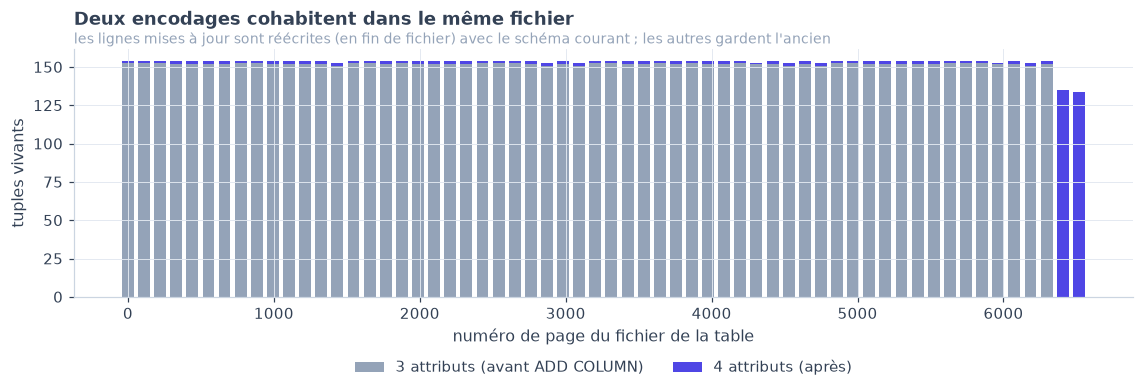

In [4]:
fin = q("SELECT pg_relation_size('clients') / 8192")[0][0]
echantillon = sorted(set(np.linspace(0, fin - 1, 60).astype(int)))
rows = []
for p in echantillon:
    r = q("""SELECT count(*) FILTER (WHERE t_infomask2 & 2047 = 3), count(*) FILTER (WHERE t_infomask2 & 2047 = 4)
             FROM heap_page_items(get_raw_page('clients', %s)) WHERE lp_flags = 1 AND t_xmax = 0""", (int(p),))[0]
    rows.append((p, *r))
pg = pd.DataFrame(rows, columns=["page", "3 attributs (avant ADD COLUMN)", "4 attributs (après)"])
fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.bar(pg.page, pg.iloc[:, 1], width=fin / 80, color=GRAY, label=pg.columns[1])
ax.bar(pg.page, pg.iloc[:, 2], bottom=pg.iloc[:, 1], width=fin / 80, color=INDIGO, label=pg.columns[2])
ax.set_xlabel("numéro de page du fichier de la table"); ax.set_ylabel("tuples vivants")
ax.set_title("Deux encodages cohabitent dans le même fichier")
subtitle(ax, "les lignes mises à jour sont réécrites (en fin de fichier) avec le schéma courant ; les autres gardent l'ancien")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.show()

Les pages d'origine contiennent surtout des tuples à 3 attributs (l'ancien encodage) ;
les versions réécrites par les `UPDATE` ont 4 attributs et s'entassent à la fin du
fichier (MVCC : une mise à jour écrit une nouvelle version, chapitre 7).
Les données survivent au code, physiquement : la même table contient deux formats de
ligne, et le moteur sait lire les deux.

> **À retenir.** Sur le disque, chaque ligne garde l'encodage de sa dernière écriture ;
> c'est le moteur qui réconcilie les époques à la lecture.

## 3. Les changements qui réécrivent toute la table

D'autres changements obligent PostgreSQL à **réécrire** chaque ligne : changer le type
d'une colonne vers un type d'encodage différent, ou ajouter une colonne dont le défaut est
**volatil** (différent pour chaque ligne). Mesurons la durée et observons le fichier, pour
plusieurs tailles de table.

In [5]:
def mesurer(n):
    con.execute("DROP TABLE IF EXISTS essai")
    con.execute("CREATE TABLE essai (id int PRIMARY KEY, nom text, solde numeric(12, 2))")
    con.execute("INSERT INTO essai SELECT i, 'c' || i, i * 0.5 FROM generate_series(1, %s) AS i", (n,))
    con.execute("VACUUM ANALYZE essai")
    res = {"lignes": n}
    for nom, sql in [("ADD COLUMN défaut constant", "ALTER TABLE essai ADD COLUMN a text DEFAULT 'x'"),
                     ("ADD COLUMN défaut volatil", "ALTER TABLE essai ADD COLUMN b double precision DEFAULT random()"),
                     ("ALTER COLUMN TYPE int -> bigint", "ALTER TABLE essai ALTER COLUMN id TYPE bigint")]:
        f0 = fichier("essai")[0]
        t = time.perf_counter()
        con.execute(sql)
        res[nom + " (ms)"] = (time.perf_counter() - t) * 1e3
        res[nom + " : réécrit ?"] = fichier("essai")[0] != f0
    return res

mes = pd.DataFrame([mesurer(n) for n in [50_000, 200_000, 800_000]])
mes.round(1)

,lignes,ADD COLUMN défaut constant (ms),ADD COLUMN défaut constant : réécrit ?,ADD COLUMN défaut volatil (ms),ADD COLUMN défaut volatil : réécrit ?,ALTER COLUMN TYPE int -> bigint (ms),ALTER COLUMN TYPE int -> bigint : réécrit ?
0,50000,0.4,False,20.3,True,20.2,True
1,200000,0.4,False,78.5,True,79.7,True
2,800000,0.4,False,342.7,True,303.8,True


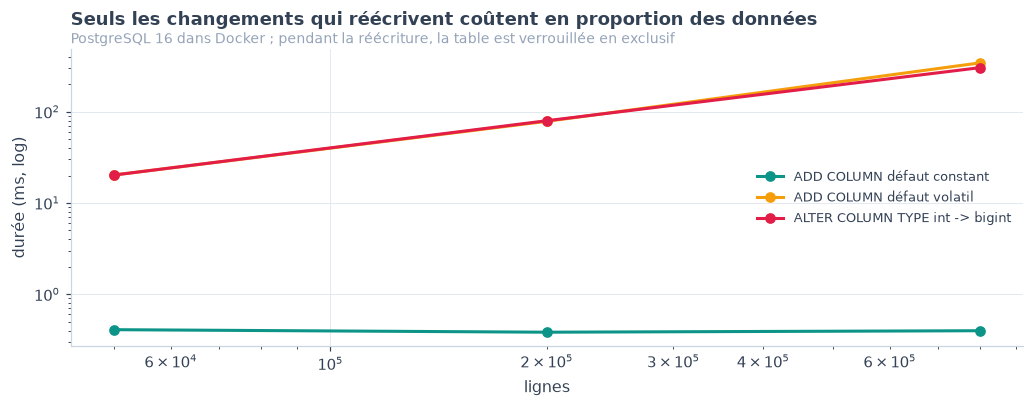

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for col, c in [("ADD COLUMN défaut constant (ms)", TEAL), ("ADD COLUMN défaut volatil (ms)", AMBER),
               ("ALTER COLUMN TYPE int -> bigint (ms)", ROSE)]:
    ax.loglog(mes.lignes, mes[col], "o-", color=c, label=col.replace(" (ms)", ""))
ax.set_xlabel("lignes"); ax.set_ylabel("durée (ms, log)")
ax.set_title("Seuls les changements qui réécrivent coûtent en proportion des données")
subtitle(ax, "PostgreSQL 16 dans Docker ; pendant la réécriture, la table est verrouillée en exclusif")
ax.legend(loc="center right", fontsize=8.5)
plt.tight_layout(); plt.show()

Le défaut constant reste instantané ; le défaut volatil et le changement de type
réécrivent la table (nouveau fichier) et croissent linéairement avec sa taille. Sur une
table de plusieurs centaines de gigaoctets, une telle réécriture prend des heures pendant
lesquelles la table est verrouillée : d'où les migrations en ligne par étapes du cours 4
(nouvelle colonne, double écriture, rattrapage par lots, bascule).